In [ ]:
train_dir =r'/deepglobe/train'
test_dir=r'/deepglobe/test'

In [ ]:
import tensorflow as tf
from tensorflow.keras import initializers
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import random
seed=14
np.random.seed=seed
img_width=512
img_height=512
img_channels=3

In [ ]:
train_img_dir = os.path.join(train_dir,'images/')
train_mask_dir = os.path.join(train_dir,'masks/')
test_img_dir = os.path.join(test_dir,'images/')
test_mask_dir = os.path.join(test_dir,'masks/')

In [ ]:
print(train_img_dir)
test_img_count = len(os.listdir(test_img_dir))
train_img_count=len(os.listdir(train_img_dir))
train_img_ids = os.listdir(train_img_dir)
test_img_ids = os.listdir(test_img_dir)
train_mask_count=len(os.listdir(train_mask_dir))
train_mask_ids=os.listdir(train_mask_dir)
print('Train image count is',train_img_count,'and their ids are',train_img_ids)
print('Mask image count is',train_mask_count,'and theur ids are',train_mask_ids)

/content/drive/MyDrive/deepglobe/train/images/
Train image count is 6200 and their ids are ['img-5201.png', 'img-5202.png', 'img-5204.png', 'img-5205.png', 'img-5203.png', 'img-5206.png', 'img-5208.png', 'img-5207.png', 'img-5209.png', 'img-5211.png', 'img-5210.png', 'img-5212.png', 'img-5213.png', 'img-5215.png', 'img-5214.png', 'img-5216.png', 'img-5218.png', 'img-5217.png', 'img-5219.png', 'img-5220.png', 'img-5221.png', 'img-5222.png', 'img-5223.png', 'img-5224.png', 'img-5225.png', 'img-5226.png', 'img-5227.png', 'img-5228.png', 'img-5229.png', 'img-5232.png', 'img-5231.png', 'img-5230.png', 'img-5233.png', 'img-5235.png', 'img-5234.png', 'img-5236.png', 'img-5237.png', 'img-5240.png', 'img-5239.png', 'img-5238.png', 'img-5243.png', 'img-5241.png', 'img-5242.png', 'img-5244.png', 'img-5245.png', 'img-5246.png', 'img-5247.png', 'img-5249.png', 'img-5248.png', 'img-5251.png', 'img-5250.png', 'img-5253.png', 'img-5254.png', 'img-5252.png', 'img-5257.png', 'img-5255.png', 'img-5256.pn

In [ ]:
test_img_count=len(os.listdir(test_img_dir))
test_img_ids=os.listdir(test_img_dir)

In [ ]:
test_img_count = len(os.listdir(test_img_dir))
test_img_ids = os.listdir(test_img_dir)
print('Test image count is',test_img_count,'and their ids are',test_img_ids)

Test image count is 26 and their ids are ['img-6201.png', 'img-6202.png', 'img-6203.png', 'img-6204.png', 'img-6205.png', 'img-6206.png', 'img-6208.png', 'img-6207.png', 'img-6210.png', 'img-6209.png', 'img-6212.png', 'img-6211.png', 'img-6213.png', 'img-6214.png', 'img-6215.png', 'img-6218.png', 'img-6217.png', 'img-6216.png', 'img-6219.png', 'img-6220.png', 'img-6222.png', 'img-6221.png', 'img-6224.png', 'img-6223.png', 'img-6226.png', 'img-6225.png']


In [ ]:
X_train = np.zeros((train_mask_count,img_width,img_height,img_channels),dtype=np.uint8)
y_train = np.zeros((len(train_mask_ids),img_width,img_height,1),dtype=np.bool_)

In [ ]:
print('Resizing train images and masks')
for n,img_name in tqdm(enumerate(train_mask_ids),total=len(train_mask_ids)):
    path = train_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_train[n] = img
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(train_mask_dir+img_name)
    # Ensure the mask is single channel before resizing and expanding dimensions
    if msk.ndim == 3 and msk.shape[-1] == 3: # If it's a 3-channel image, take one channel
        msk = msk[:,:,0]
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_train[n] = mask

Resizing train images and masks


100%|██████████| 6200/6200 [1:15:59<00:00,  1.36it/s]


In [ ]:
X_test = np.zeros((test_img_count,img_width,img_height,img_channels),dtype=np.uint8)
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)


In [ ]:
print('Resizing test images')
for i,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    path = test_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_test[i] = img

Resizing test images


100%|██████████| 26/26 [00:18<00:00,  1.37it/s]


In [ ]:
print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_width,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    # Ensure the mask is single channel before resizing and expanding dimensions
    if msk.ndim == 3 and msk.shape[-1] == 3: # If it's a 3-channel image, take one channel
        msk = msk[:,:,0]
    msk = np.expand_dims(resize(msk,(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 26/26 [00:17<00:00,  1.47it/s]


In [ ]:
input_shape = (img_height, img_width, img_channels)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import vgg19


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers


class DirectionalAttention(layers.Layer):
    def __init__(self, filters, **kwargs):
        super().__init__(**kwargs)

        self.filters = filters

        # Four directional convolution branches
        self.conv_0 = layers.Conv2D(
            filters, (1, 7), padding="same", use_bias=False
        )
        self.conv_45 = layers.Conv2D(
            filters, (7, 7), padding="same", use_bias=False
        )
        self.conv_90 = layers.Conv2D(
            filters, (7, 1), padding="same", use_bias=False
        )
        self.conv_135 = layers.Conv2D(
            filters, (7, 7), padding="same", use_bias=False
        )

        self.alpha = self.add_weight(
            name="direction_weights",
            shape=(4,),
            initializer="ones",
            trainable=True
        )

    def build(self, input_shape):
        # Explicitly build all convolution layers first
        self.conv_0.build(input_shape)
        self.conv_45.build(input_shape)
        self.conv_90.build(input_shape)
        self.conv_135.build(input_shape)

        # Main-diagonal and anti-diagonal masks
        main_diag = tf.eye(7, dtype=tf.float32)
        anti_diag = tf.reverse(main_diag, axis=[1])

        # Broadcast across input and output channels
        in_channels = int(input_shape[-1])
        self.mask_45 = tf.reshape(
            main_diag, (7, 7, 1, 1)
        )
        self.mask_135 = tf.reshape(
            anti_diag, (7, 7, 1, 1)
        )

        super().build(input_shape)

    def call(self, x):
        f0 = self.conv_0(x)
        f90 = self.conv_90(x)

        # Apply diagonal masks to the built convolution kernels
        kernel_45 = self.conv_45.kernel * self.mask_45
        kernel_135 = self.conv_135.kernel * self.mask_135

        f45 = tf.nn.conv2d(
            x, kernel_45,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )
        f135 = tf.nn.conv2d(
            x, kernel_135,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

        # Softmax-normalized directional fusion
        alpha = tf.nn.softmax(self.alpha)

        out = (
            alpha[0] * f0 +
            alpha[1] * f45 +
            alpha[2] * f90 +
            alpha[3] * f135
        )

        return out

    def get_config(self):
        config = super().get_config()
        config.update({"filters": self.filters})
        return config


In [ ]:
class TransformerBlock(layers.Layer):
    def __init__(self, dim, num_heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = layers.LayerNormalization()
        self.attn = layers.MultiHeadAttention(num_heads, key_dim=dim)
        self.norm2 = layers.LayerNormalization()
        self.mlp = tf.keras.Sequential([
            layers.Dense(dim * mlp_ratio, activation='gelu'),
            layers.Dense(dim)
        ])

    def call(self, x):
        h = x
        x = self.norm1(x)
        x = self.attn(x, x)
        x = h + x

        h = x
        x = self.norm2(x)
        x = self.mlp(x)
        return h + x


In [ ]:
def hybrid_bottleneck(x, filters):
    b, h, w, c = x.shape
    x_flat = layers.Reshape((h * w, c))(x)

    x_trans = TransformerBlock(c)(x_flat)
    x_trans = layers.Reshape((h, w, c))(x_trans)

    x = layers.Concatenate()([x, x_trans])
    x = layers.Conv2D(filters, 1, activation='relu')(x)
    x=layers.BatchNormalization()(x)
    return x


In [ ]:
def decoder_block(x, skip, filters):
    x = layers.UpSampling2D()(x)
    x = layers.Concatenate()([x, skip])

    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    return x

In [ ]:
# def decoder_block(x, skip, filters):
#     x = layers.UpSampling2D()(x)
#     x = layers.Concatenate()([x, skip])
#     x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
#     x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
#     return x


In [ ]:
def TopoRoadNet(input_shape=(512, 512, 3)):
    inputs = layers.Input(input_shape)

    # Encoder (ResNet)
    base = vgg19.VGG19(include_top=False, weights='imagenet', input_tensor=inputs)

    e1 = base.get_layer("block1_conv2").output # Use a suitable layer from VGG19, 'conv1_relu' is not a VGG19 layer name
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    # Directional Attention
    e4 = DirectionalAttention(512)(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, 512)

    # Decoder
    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    # The previous UpSampling2D was causing the output to be 1024x1024.
    # d2 is already 512x512, so it can directly feed into the final convolution.
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d2)

    return models.Model(inputs, outputs, name="TopoRoadNet")

In [ ]:
X_train = X_train.astype("float32")
X_test  = X_test.astype("float32")

# Normalize if needed
if X_train.max() > 1.0:
    X_train /= 255.0
    X_test  /= 255.0


In [ ]:
if y_train.ndim == 3:
    y_train = np.expand_dims(y_train, axis=-1)

if y_test_ground_truth.ndim == 3:
    y_test_ground_truth = np.expand_dims(y_test_ground_truth, axis=-1)

y_train = y_train.astype("float32")
y_test_ground_truth = y_test_ground_truth.astype("float32")

In [ ]:
model = TopoRoadNet(input_shape=X_train.shape[1:])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
#     loss=total_loss,
#     metrics=[
#         tf.keras.metrics.BinaryAccuracy(name="accuracy"),
#         tf.keras.metrics.MeanIoU(num_classes=2, name="IoU")
#     ]
# )

model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "TopoRoadNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 512, 512,  │      1,792 │ input_layer[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 512, 512,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 256, 256,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 256, 256,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 256, 256,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 128, 128,  │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 128, 128,  │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 128, 128,  │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 128, 128,  │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv4        │ (None, 128, 128,  │    590,080 │ block3_conv3[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 64, 64,    │          0 │ block3_conv4[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 64, 64,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 64, 64,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 64, 64,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv4        │ (None, 64, 64,    │  2,359,808 │ block4_conv3[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ directional_attent… │ (None, 64, 64,    │ 29,360,132 │ block4_conv4[0][

 Total params: 54,075,525 (206.28 MB)

 Trainable params: 54,072,709 (206.27 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet_best.h5",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]


In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,   # 80% train, 20% validation
    batch_size=4,
    epochs=100,
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9300 - loss: 0.2225
Epoch 1: val_loss improved from None to 0.09545, saving model to toporoadnet_best.h5



Epoch 1: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 374s 206ms/step - accuracy: 0.9555 - loss: 0.1489 - val_accuracy: 0.9674 - val_loss: 0.0954 - learning_rate: 1.0000e-04
Epoch 2/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9691 - loss: 0.0901
Epoch 2: val_loss improved from 0.09545 to 0.08026, saving model to toporoadnet_best.h5



Epoch 2: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 236s 191ms/step - accuracy: 0.9696 - loss: 0.0861 - val_accuracy: 0.9706 - val_loss: 0.0803 - learning_rate: 1.0000e-04
Epoch 3/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9718 - loss: 0.0753
Epoch 3: val_loss did not improve from 0.08026
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 190ms/step - accuracy: 0.9724 - loss: 0.0734 - val_accuracy: 0.9626 - val_loss: 0.1008 - learning_rate: 1.0000e-04
Epoch 4/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9740 - loss: 0.0677
Epoch 4: val_loss improved from 0.08026 to 0.07178, saving model to toporoadnet_best.h5



Epoch 4: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 237s 191ms/step - accuracy: 0.9740 - loss: 0.0674 - val_accuracy: 0.9720 - val_loss: 0.0718 - learning_rate: 1.0000e-04
Epoch 5/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9751 - loss: 0.0637
Epoch 5: val_loss improved from 0.07178 to 0.06438, saving model to toporoadnet_best.h5



Epoch 5: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 237s 191ms/step - accuracy: 0.9753 - loss: 0.0630 - val_accuracy: 0.9747 - val_loss: 0.0644 - learning_rate: 1.0000e-04
Epoch 6/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9765 - loss: 0.0594
Epoch 6: val_loss did not improve from 0.06438
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9765 - loss: 0.0595 - val_accuracy: 0.9744 - val_loss: 0.0650 - learning_rate: 1.0000e-04
Epoch 7/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9773 - loss: 0.0573
Epoch 7: val_loss improved from 0.06438 to 0.06332, saving model to toporoadnet_best.h5



Epoch 7: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 236s 191ms/step - accuracy: 0.9773 - loss: 0.0573 - val_accuracy: 0.9753 - val_loss: 0.0633 - learning_rate: 1.0000e-04
Epoch 8/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9783 - loss: 0.0543
Epoch 8: val_loss improved from 0.06332 to 0.06019, saving model to toporoadnet_best.h5



Epoch 8: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 236s 191ms/step - accuracy: 0.9783 - loss: 0.0544 - val_accuracy: 0.9760 - val_loss: 0.0602 - learning_rate: 1.0000e-04
Epoch 9/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9799 - loss: 0.0501
Epoch 9: val_loss did not improve from 0.06019
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9792 - loss: 0.0519 - val_accuracy: 0.9760 - val_loss: 0.0609 - learning_rate: 1.0000e-04
Epoch 10/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9801 - loss: 0.0492
Epoch 10: val_loss did not improve from 0.06019
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9801 - loss: 0.0495 - val_accuracy: 0.9760 - val_loss: 0.0612 - learning_rate: 1.0000e-04
Epoch 11/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9807 - loss: 0.0477
Epoch 11: val_loss did not improve from 0.06019
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9809 - loss: 


Epoch 12: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 237s 191ms/step - accuracy: 0.9820 - loss: 0.0443 - val_accuracy: 0.9765 - val_loss: 0.0600 - learning_rate: 1.0000e-04
Epoch 13/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9830 - loss: 0.0416
Epoch 13: val_loss did not improve from 0.05995
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9829 - loss: 0.0419 - val_accuracy: 0.9757 - val_loss: 0.0655 - learning_rate: 1.0000e-04
Epoch 14/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9838 - loss: 0.0395
Epoch 14: val_loss improved from 0.05995 to 0.05985, saving model to toporoadnet_best.h5



Epoch 14: finished saving model to toporoadnet_best.h5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 237s 191ms/step - accuracy: 0.9838 - loss: 0.0394 - val_accuracy: 0.9774 - val_loss: 0.0599 - learning_rate: 1.0000e-04
Epoch 15/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9848 - loss: 0.0367
Epoch 15: val_loss did not improve from 0.05985
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 189ms/step - accuracy: 0.9846 - loss: 0.0374 - val_accuracy: 0.9776 - val_loss: 0.0620 - learning_rate: 1.0000e-04
Epoch 16/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9859 - loss: 0.0341
Epoch 16: val_loss did not improve from 0.05985
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 235s 190ms/step - accuracy: 0.9857 - loss: 0.0345 - val_accuracy: 0.9783 - val_loss: 0.0624 - learning_rate: 1.0000e-04
Epoch 17/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9869 - loss: 0.0313
Epoch 17: val_loss did not improve from 0.05985

Epoch 17: ReduceLROnPlateau reducing learning rate to 1.99999994947575

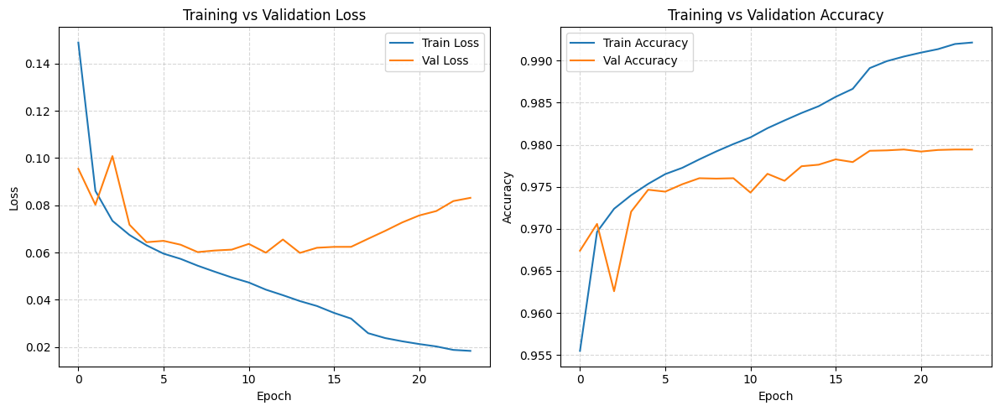

In [ ]:
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(18, 5))

# ---- LOSS ----
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# ---- ACCURACY ----
plt.subplot(1, 3, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# ---- IoU ----

plt.tight_layout()
plt.show()


In [ ]:
test_results = model.evaluate(
    X_test,
    y_test_ground_truth,
    batch_size=4,
    verbose=1
)

print("Test Loss:", test_results[0])
print("Test Accuracy:", test_results[1])
#print("Test IoU:", test_results[2])


7/7 ━━━━━━━━━━━━━━━━━━━━ 37s 5s/step - accuracy: 0.9790 - loss: 0.0544
Test Loss: 0.05440978333353996
Test Accuracy: 0.9790242910385132


In [ ]:
Y_pred = model.predict(X_test, batch_size=4)
Y_pred_bin = (Y_pred > 0.3).astype("uint8")


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 811ms/step


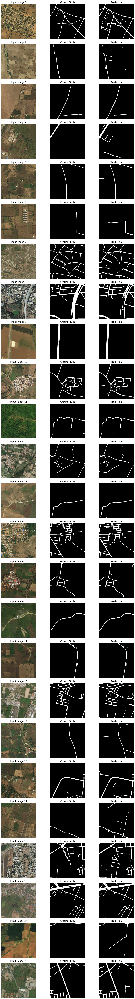

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

num_images = 25
indices = np.random.choice(len(X_test), num_images, replace=False)

plt.figure(figsize=(12, num_images * 3))

for i, idx in enumerate(indices):
    # Input Image
    plt.subplot(num_images, 3, i*3 + 1)
    plt.imshow(X_test[idx])
    plt.title(f"Input Image {i+1}")
    plt.axis("off")

    # Ground Truth
    plt.subplot(num_images, 3, i*3 + 2)
    plt.imshow(y_test_ground_truth[idx].squeeze(), cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    # Prediction
    plt.subplot(num_images, 3, i*3 + 3)
    plt.imshow(Y_pred_bin[idx].squeeze(), cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
def overlay_mask(image, mask, alpha=0.5):
    overlay = image.copy()
    overlay[mask.squeeze() == 1] = [1.0, 0.0, 0.0]  # Red roads
    return (1 - alpha) * image + alpha * overlay


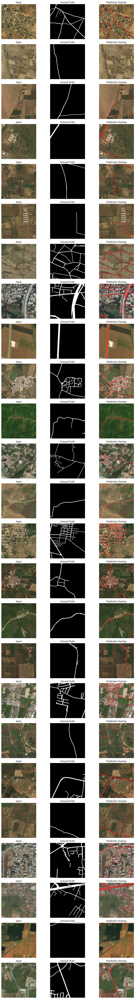

In [ ]:
plt.figure(figsize=(12, num_images * 3))

for i, idx in enumerate(indices):
    overlay_img = overlay_mask(X_test[idx], Y_pred_bin[idx])

    plt.subplot(num_images, 3, i*3 + 1)
    plt.imshow(X_test[idx])
    plt.title("Input")
    plt.axis("off")

    plt.subplot(num_images, 3, i*3 + 2)
    plt.imshow(y_test_ground_truth[idx].squeeze(), cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_images, 3, i*3 + 3)
    plt.imshow(overlay_img)
    plt.title("Prediction Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 74s 74s/step
===== PIXEL-LEVEL EVALUATION METRICS =====
Precision       : 0.7061
Recall          : 0.8280
F1-score        : 0.7622
IoU             : 0.6158
Overall Accuracy: 0.9756
Kappa (κ)       : 0.7494



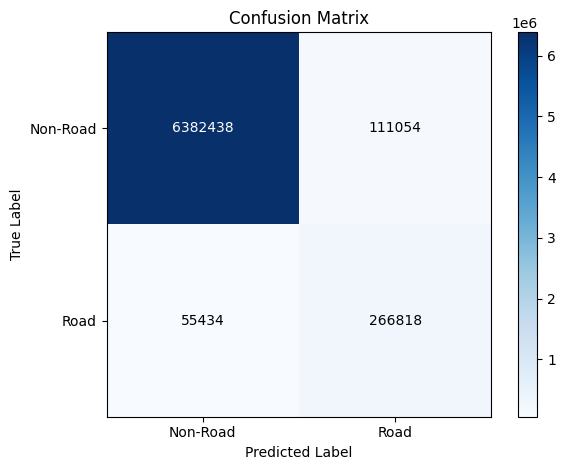

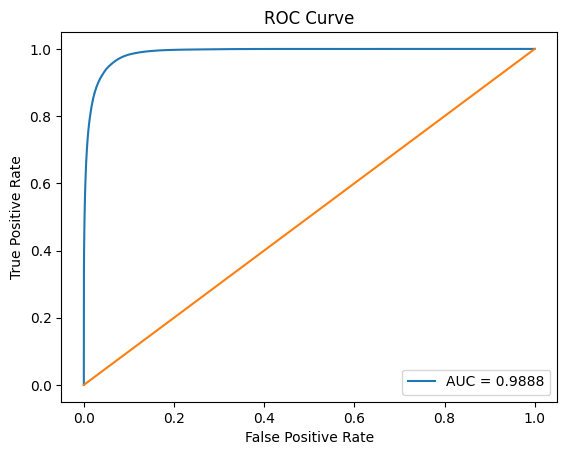

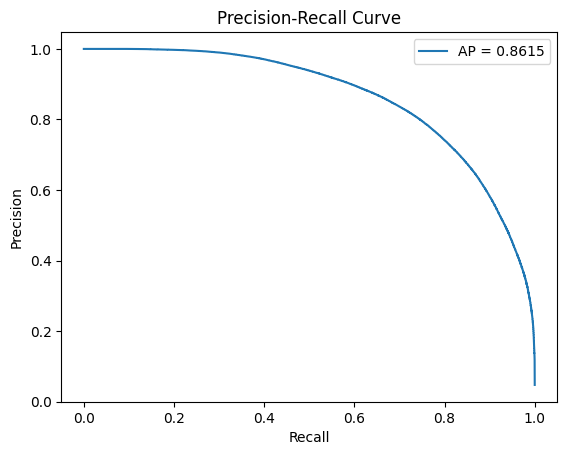

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

Y_pred_prob = model.predict(X_test)

# Flatten
y_true = y_test_ground_truth.flatten().astype(np.uint8)
y_scores = Y_pred_prob.flatten()

# Binary threshold
Y_pred_bin = (Y_pred_prob > 0.3).astype(np.uint8)
y_pred = Y_pred_bin.flatten()# ===============================
# Confusion Matrix Components
# ===============================
TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

precision = TP / (TP + FP + 1e-8)
recall    = TP / (TP + FN + 1e-8)
f1_score  = 2 * precision * recall / (precision + recall + 1e-8)
iou       = TP / (TP + FP + FN + 1e-8)
accuracy  = (TP + TN) / (TP + TN + FP + FN)

total = TP + TN + FP + FN
po = accuracy
pe = (((TP + FP) * (TP + FN)) + ((FN + TN) * (FP + TN))) / (total ** 2)
kappa = (po - pe) / (1 - pe + 1e-8)

print("===== PIXEL-LEVEL EVALUATION METRICS =====")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-score        : {f1_score:.4f}")
print(f"IoU             : {iou:.4f}")
print(f"Overall Accuracy: {accuracy:.4f}")
print(f"Kappa (κ)       : {kappa:.4f}")
print("=========================================\n")

# ===============================
# 1️⃣ Confusion Matrix (White-Blue)
# ===============================
cm = confusion_matrix(y_true, y_pred)

plt.figure()
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()

classes = ["Non-Road", "Road"]
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, f"{cm[i, j]}",
                 ha="center",
                 va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.tight_layout()
plt.show()


# ===============================
# 2️⃣ ROC Curve
# ===============================
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# ===============================
# 3️⃣ Precision-Recall Curve
# ===============================
precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall_vals, precision_vals)

plt.figure()
plt.plot(recall_vals, precision_vals, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

Tuning on validation images...
  thr=0.30 gap= 0 spur= 0 -> val APLS 0.5334
  thr=0.30 gap= 0 spur=10 -> val APLS 0.5411
  thr=0.30 gap=20 spur= 0 -> val APLS 0.5328
  thr=0.30 gap=20 spur=10 -> val APLS 0.5409
  thr=0.40 gap= 0 spur= 0 -> val APLS 0.4870
  thr=0.40 gap= 0 spur=10 -> val APLS 0.4858
  thr=0.40 gap=20 spur= 0 -> val APLS 0.4966
  thr=0.40 gap=20 spur=10 -> val APLS 0.4923
  thr=0.50 gap= 0 spur= 0 -> val APLS 0.4302
  thr=0.50 gap= 0 spur=10 -> val APLS 0.4282
  thr=0.50 gap=20 spur= 0 -> val APLS 0.4500
  thr=0.50 gap=20 spur=10 -> val APLS 0.4455
Best settings: {'thr': 0.3, 'max_gap': 0, 'spur': 10}  (val APLS 0.5411)

Image 001 - APLS: 0.0752
Image 002 - APLS: 0.9976
Image 003 - APLS: 0.9966
Image 004 - APLS: 0.6927
Image 005 - APLS: 0.6679
Image 006 - APLS: 0.2680
Image 007 - APLS: 0.6142
Image 008 - APLS: 0.5012
Image 009 - APLS: 0.0000
Image 010 - APLS: 0.3886
Image 011 - APLS: 0.6448
Image 012 - APLS: 0.5233
Image 013 - APLS: 0.6439
Image 014 - APLS: 0.0000
Image

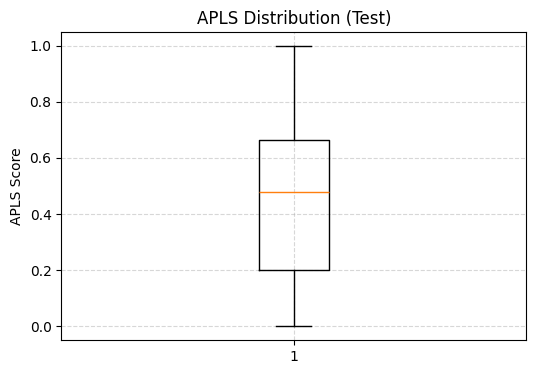

In [ ]:
# ============ APLS EVALUATION: improved, single cell ============
# Needs: model, X_test, y_test_ground_truth, X_train, y_train

import numpy as np, networkx as nx, random, itertools, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.ndimage import convolve
from skimage.morphology import skeletonize, remove_small_objects, binary_closing, disk
from skimage.measure import label
from skimage.draw import line

# ---------------- Settings ----------------
USE_TTA   = True            # 8x flip/rotate averaging (slower, better)
TUNE      = True            # tune postprocessing on VALIDATION data (not test)
N_VAL     = 20              # validation images used for tuning
GRID_THR  = (0.3, 0.4, 0.5)
GRID_GAP  = (0, 20)         # max gap (px) to bridge
GRID_SPUR = (0, 10)         # spur length (px) to prune
DEFAULT   = dict(thr=0.4, max_gap=20, spur=10)   # used if TUNE=False
MIN_SIZE, CLOSE_R = 150, 2
BUFFER, N_NODES, SEED = 4, 60, 42

# ---------------- Prediction (optional TTA) ----------------
def predict_probs(X, bs=4):
    if not USE_TTA:
        return model.predict(X, batch_size=bs, verbose=0)
    out = np.zeros(X.shape[:3] + (1,), np.float32)
    for k in range(4):
        for flip in (False, True):
            x = np.rot90(X, k, axes=(1, 2))
            if flip: x = x[:, :, ::-1]
            p = model.predict(np.ascontiguousarray(x), batch_size=bs, verbose=0)
            if flip: p = p[:, :, ::-1]
            out += np.rot90(p, -k, axes=(1, 2))
    return out / 8.0

# ---------------- Mask -> skeleton -> graph ----------------
def bridge_gaps(skel, max_gap):
    if max_gap <= 0: return skel
    skel = skel.copy()
    pts = np.argwhere(skel)
    if len(pts) < 2: return skel
    lab = label(skel, connectivity=2)
    nb = convolve(skel.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant") - 1
    ends = np.argwhere(skel & (nb == 1))
    tree = cKDTree(pts)
    kq = min(100, len(pts))
    for y, x in ends:
        d, j = tree.query([y, x], k=kq, distance_upper_bound=max_gap)
        for dd, jj in zip(np.atleast_1d(d), np.atleast_1d(j)):
            if np.isinf(dd): break
            py, px = pts[jj]
            if lab[py, px] != lab[y, x]:           # different component -> connect
                rr, cc = line(y, x, py, px); skel[rr, cc] = True
                break
    return skeletonize(skel)

def pred_to_skeleton(prob, thr, max_gap):
    m = prob.squeeze() > thr
    if CLOSE_R > 0: m = binary_closing(m, disk(CLOSE_R))
    if MIN_SIZE > 0: m = remove_small_objects(m, MIN_SIZE)
    return bridge_gaps(skeletonize(m), max_gap)

def skel_to_graph(skel):
    pts = set(map(tuple, np.argwhere(skel)[:, ::-1]))      # (x, y)
    G = nx.Graph(); G.add_nodes_from(pts)
    for (x, y) in pts:
        for dx, dy in ((1, 0), (0, 1), (1, 1), (1, -1)):   # each pair once
            q = (x + dx, y + dy)
            if q in pts: G.add_edge((x, y), q, weight=float(np.hypot(dx, dy)))
    return G

def prune_spurs(G, min_len):
    if min_len <= 0: return G
    G = G.copy()
    for n in [n for n in G.nodes if G.degree(n) == 1]:
        if n not in G: continue
        path, cur, prev = [n], n, None
        while True:
            nxt = [m for m in G.neighbors(cur) if m != prev]
            if len(nxt) != 1: break
            prev, cur = cur, nxt[0]; path.append(cur)
            if G.degree(cur) != 2: break
        if G.degree(cur) >= 3 and len(path) < min_len:
            G.remove_nodes_from(path[:-1])                  # keep the junction
    return G

def key_nodes(G): return [n for n in G.nodes if G.degree(n) != 2]

# ---------------- APLS (symmetric, snapped, normalised by GT length) ----------------
def apls_one_direction(G_a, G_b):
    nodes = key_nodes(G_a)
    if len(nodes) < 2: return None
    if G_b.number_of_nodes() == 0: return 0.0
    nodes = random.Random(SEED).sample(nodes, min(N_NODES, len(nodes)))
    b_nodes = list(G_b.nodes)
    dist, idx = cKDTree(np.array(b_nodes)).query(np.array(nodes))
    snap = [b_nodes[i] if d <= BUFFER else None for d, i in zip(dist, idx)]
    scores = []
    for i in range(len(nodes)):
        len_a = nx.single_source_dijkstra_path_length(G_a, nodes[i], weight="weight")
        len_b = (nx.single_source_dijkstra_path_length(G_b, snap[i], weight="weight")
                 if snap[i] is not None else {})
        for j in range(i + 1, len(nodes)):
            if nodes[j] not in len_a: continue              # no route in reference
            L_a = len_a[nodes[j]]
            if L_a == 0: continue
            if snap[i] is None or snap[j] is None or snap[j] not in len_b:
                scores.append(0.0)
            else:
                scores.append(1.0 - min(1.0, abs(L_a - len_b[snap[j]]) / L_a))
    return float(np.mean(scores)) if scores else None

def apls(G_gt, G_pr):
    p = apls_one_direction(G_gt, G_pr)                      # missed roads
    if p is None: return np.nan
    q = apls_one_direction(G_pr, G_gt); q = 0.0 if q is None else q   # false roads
    return 2 * p * q / (p + q + 1e-8)

def evaluate(probs, gts, thr, max_gap, spur, verbose=False):
    scores = []
    for i in range(len(probs)):
        G_gt = skel_to_graph(skeletonize(gts[i].squeeze() > 0.5))
        G_pr = prune_spurs(skel_to_graph(pred_to_skeleton(probs[i], thr, max_gap)), spur)
        s = apls(G_gt, G_pr); scores.append(s)
        if verbose:
            print(f"Image {i+1:03d} - APLS: {s:.4f}" if not np.isnan(s)
                  else f"Image {i+1:03d} - skipped (no GT roads)")
    return np.array(scores)

# ---------------- Tune on validation (never on test) ----------------
best = DEFAULT
if TUNE:
    if "va_idx" in globals():
        val_ids = va_idx
    else:                                                    # matches Keras validation_split=0.2
        val_ids = np.arange(int(len(X_train) * 0.8), len(X_train))
    val_ids = val_ids[:N_VAL]
    Pv, Gv = predict_probs(X_train[val_ids]), y_train[val_ids]
    best_score = -1
    print("Tuning on validation images...")
    for thr, gap, sp in itertools.product(GRID_THR, GRID_GAP, GRID_SPUR):
        sc = np.nanmean(evaluate(Pv, Gv, thr, gap, sp))
        print(f"  thr={thr:.2f} gap={gap:2d} spur={sp:2d} -> val APLS {sc:.4f}")
        if sc > best_score: best_score, best = sc, dict(thr=thr, max_gap=gap, spur=sp)
    print(f"Best settings: {best}  (val APLS {best_score:.4f})\n")

# ---------------- Final test evaluation ----------------
Y_pred_prob = predict_probs(X_test)
scores = evaluate(Y_pred_prob, y_test_ground_truth, verbose=True, **best)
valid = scores[~np.isnan(scores)]

print("\n=========== APLS SUMMARY (TEST) ===========")
print(f"Settings         : {best}")
print(f"Images evaluated : {len(valid)} / {len(scores)}")
print(f"Mean APLS        : {valid.mean():.4f}")
print(f"Median APLS      : {np.median(valid):.4f}")
print(f"Std              : {valid.std():.4f}")
print("===========================================")

plt.figure(figsize=(6, 4)); plt.boxplot(valid)
plt.ylabel("APLS Score"); plt.title("APLS Distribution (Test)")
plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0


def TopoRoadNet2(input_shape=(512, 512, 3)):
    inputs = layers.Input(shape=input_shape, name="input_image")

    # Encoder: EfficientNetB0
    base = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    # Multi-scale encoder features
    e1 = base.get_layer("block1a_project_bn").output  # 256 x 256
    e2 = base.get_layer("block2b_add").output         # 128 x 128
    e3 = base.get_layer("block3b_add").output         # 64 x 64
    e4 = base.get_layer("block5c_add").output         # 32 x 32

    # Directional Attention
    e4 = DirectionalAttention(112)(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, 112)

    # Decoder
    d4 = decoder_block(b, e3, 96)
    d3 = decoder_block(d4, e2, 64)
    d2 = decoder_block(d3, e1, 32)

    # Upsample to the original input resolution
    d1 = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(d2)

    # Road segmentation output
    outputs = layers.Conv2D(
        filters=1,
        kernel_size=1,
        activation="sigmoid",
        name="road_segmentation"
    )(d1)

    return models.Model(
        inputs=inputs,
        outputs=outputs,
        name="TopoRoadNet2_EfficientNetB0"
    )

In [ ]:
# Build EfficientNetB0-based TopoRoadNet2
model_efficientnet = TopoRoadNet2(
    input_shape=X_train.shape[1:]
)

# Compile the model
model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# Alternative compilation using your custom loss
# model_efficientnet.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
#     loss=total_loss,
#     metrics=[
#         tf.keras.metrics.BinaryAccuracy(name="accuracy"),
#         tf.keras.metrics.MeanIoU(num_classes=2, name="IoU")
#     ]
# )

# Display architecture
model_efficientnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "TopoRoadNet2_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 512, 512,  │          0 │ input_image[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 512, 512,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 512, 512,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 513, 513,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 256, 256,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 256, 256,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 256, 256,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 256, 256,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 256, 256,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 256, 256,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 256, 256,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 256, 256,  │        512 │ block1a_se_excit

 Total params: 3,158,204 (12.05 MB)

 Trainable params: 3,141,045 (11.98 MB)

 Non-trainable params: 17,159 (67.03 KB)

In [ ]:
callbacks_efficientnet = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet2_efficientnetb0_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]
history_efficientnet = model_efficientnet.fit(
    X_train,
    y_train,
    validation_split=0.2,  # 80% training, 20% validation
    batch_size=4,
    epochs=100,
    callbacks=callbacks_efficientnet,
    shuffle=True
)

Epoch 1/100
1239/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9375 - loss: 0.2754
Epoch 1: val_loss improved from None to 0.33939, saving model to toporoadnet2_efficientnetb0_best.keras

Epoch 1: finished saving model to toporoadnet2_efficientnetb0_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 192s 53ms/step - accuracy: 0.9548 - loss: 0.1881 - val_accuracy: 0.9438 - val_loss: 0.3394 - learning_rate: 1.0000e-04
Epoch 2/100
1239/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9664 - loss: 0.1076
Epoch 2: val_loss improved from 0.33939 to 0.21338, saving model to toporoadnet2_efficientnetb0_best.keras

Epoch 2: finished saving model to toporoadnet2_efficientnetb0_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 48s 39ms/step - accuracy: 0.9667 - loss: 0.1019 - val_accuracy: 0.9438 - val_loss: 0.2134 - learning_rate: 1.0000e-04
Epoch 3/100
1239/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9688 - loss: 0.0879
Epoch 3: val_loss did not improve from 0.21338
1240/1240 ━━━━━━━━━━━━━━━

In [ ]:
import numpy as np

# Generate predictions using EfficientNetB0-based TopoRoadNet2
Y_pred_efficientnet = model_efficientnet.predict(
    X_test,
    batch_size=4,
    verbose=1
)

# Convert predicted probabilities to binary masks
Y_pred_bin_efficientnet = (
    Y_pred_efficientnet > 0.5
).astype(np.uint8)

# Flatten ground-truth masks and predicted masks
y_true_efficientnet = (
    y_test_ground_truth.flatten().astype(np.uint8)
)

y_pred_efficientnet_flat = (
    Y_pred_bin_efficientnet.flatten().astype(np.uint8)
)

# Confusion matrix components
TP = np.sum(
    (y_true_efficientnet == 1) &
    (y_pred_efficientnet_flat == 1)
)

TN = np.sum(
    (y_true_efficientnet == 0) &
    (y_pred_efficientnet_flat == 0)
)

FP = np.sum(
    (y_true_efficientnet == 0) &
    (y_pred_efficientnet_flat == 1)
)

FN = np.sum(
    (y_true_efficientnet == 1) &
    (y_pred_efficientnet_flat == 0)
)

# Evaluation metrics
eps = 1e-8

precision_efficientnet = TP / (TP + FP + eps)
recall_efficientnet = TP / (TP + FN + eps)

f1_efficientnet = (
    2 * precision_efficientnet * recall_efficientnet /
    (precision_efficientnet + recall_efficientnet + eps)
)

iou_efficientnet = TP / (TP + FP + FN + eps)

total = TP + TN + FP + FN

accuracy_efficientnet = (
    (TP + TN) / (total + eps)
)

# Cohen's Kappa
po = accuracy_efficientnet

pe = (
    ((TP + FP) * (TP + FN)) +
    ((FN + TN) * (FP + TN))
) / (total**2 + eps)

kappa_efficientnet = (
    (po - pe) / (1 - pe + eps)
)

# Print results
print("===== TOPOROADNET2: EFFICIENTNETB0 EVALUATION =====")
print(f"True Positives (TP): {TP}")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print("-" * 52)
print(f"Precision        : {precision_efficientnet:.4f}")
print(f"Recall           : {recall_efficientnet:.4f}")
print(f"F1-score         : {f1_efficientnet:.4f}")
print(f"IoU              : {iou_efficientnet:.4f}")
print(f"Overall Accuracy : {accuracy_efficientnet:.4f}")
print(f"Cohen's Kappa    : {kappa_efficientnet:.4f}")
print("=" * 52)

7/7 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step
===== TOPOROADNET2: EFFICIENTNETB0 EVALUATION =====
True Positives (TP): 224680
True Negatives (TN): 6446330
False Positives (FP): 47162
False Negatives (FN): 97572
----------------------------------------------------
Precision        : 0.8265
Recall           : 0.6972
F1-score         : 0.7564
IoU              : 0.6082
Overall Accuracy : 0.9788
Cohen's Kappa    : 0.7454


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ConvNeXtBase

# ============================================================
# 1. TopoRoadNet3: ConvNeXtBase feature extractor
# ============================================================

def TopoRoadNet3(input_shape=(512, 512, 3)):

    inputs = layers.Input(shape=input_shape, name="input_image")

    # Pretrained ConvNeXtBase encoder
    base = ConvNeXtBase(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )

    # Identify feature maps at 1/4, 1/8, 1/16 and 1/32 resolution
    target_sizes = [
        (input_shape[0] // 4, input_shape[1] // 4),
        (input_shape[0] // 8, input_shape[1] // 8),
        (input_shape[0] // 16, input_shape[1] // 16),
        (input_shape[0] // 32, input_shape[1] // 32)
    ]

    selected = {}

    for layer in base.layers:
        try:
            shape = tuple(layer.output.shape)
            if len(shape) == 4 and shape[1] is not None and shape[2] is not None:
                spatial = (int(shape[1]), int(shape[2]))
                if spatial in target_sizes:
                    selected[spatial] = layer.output
        except (AttributeError, ValueError, TypeError):
            continue

    missing = [s for s in target_sizes if s not in selected]

    if missing:
        raise ValueError(
            f"Could not identify ConvNeXt feature maps at {missing}. "
            "Inspect base.summary() and select the last layer at each resolution."
        )

    encoder = models.Model(
        inputs=base.input,
        outputs=[selected[s] for s in target_sizes],
        name="ConvNeXt_Encoder"
    )

    e1, e2, e3, e4 = encoder(inputs)

    # Directional Attention
    e4 = DirectionalAttention(int(e4.shape[-1]))(e4)

    # Hybrid Bottleneck
    b = hybrid_bottleneck(e4, int(e4.shape[-1]))

    # Decoder with skip connections
    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    # Upsample to original input resolution
    current_h = int(d2.shape[1])
    current_w = int(d2.shape[2])

    if current_h is None or current_w is None:
        raise ValueError("Decoder spatial dimensions must be statically known.")

    if input_shape[0] % current_h != 0 or input_shape[1] % current_w != 0:
        raise ValueError("Input and decoder dimensions do not have integer scale factors.")

    d1 = layers.UpSampling2D(
        size=(input_shape[0] // current_h, input_shape[1] // current_w),
        interpolation="bilinear"
    )(d2)

    outputs = layers.Conv2D(
        1, kernel_size=1, activation="sigmoid",
        name="road_segmentation"
    )(d1)

    return models.Model(
        inputs, outputs, name="TopoRoadNet3_ConvNeXtBase"
    )


# ============================================================
# 2. Build and compile
# ============================================================

model_convnext = TopoRoadNet3(input_shape=X_train.shape[1:])

model_convnext.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

model_convnext.summary()


# ============================================================
# 3. Callbacks
# ============================================================

callbacks_convnext = [
    tf.keras.callbacks.ModelCheckpoint(
        "toporoadnet3_convnext_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]


# ============================================================
# 4. Train
# ============================================================

history_convnext = model_convnext.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=4,
    epochs=100,
    callbacks=callbacks_convnext,
    shuffle=True
)


# ============================================================
# 5. Predict on test data
# ============================================================

Y_pred_convnext = model_convnext.predict(
    X_test,
    batch_size=4,
    verbose=1
)

Y_pred_bin_convnext = (Y_pred_convnext > 0.5).astype(np.uint8)


# ============================================================
# 6. Pixel-level evaluation
# ============================================================

y_true = np.asarray(y_test_ground_truth).flatten()
y_pred = Y_pred_bin_convnext.flatten()

# Binarize ground truth if masks use 0 and 255
if y_true.max() > 1:
    y_true = (y_true > 127).astype(np.uint8)
else:
    y_true = (y_true > 0).astype(np.uint8)

y_pred = y_pred.astype(np.uint8)

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

eps = 1e-8
total = TP + TN + FP + FN

precision_convnext = TP / (TP + FP + eps)
recall_convnext = TP / (TP + FN + eps)

f1_convnext = (
    2 * precision_convnext * recall_convnext /
    (precision_convnext + recall_convnext + eps)
)

iou_convnext = TP / (TP + FP + FN + eps)
accuracy_convnext = (TP + TN) / (total + eps)

po = accuracy_convnext
pe = (
    (TP + FP) * (TP + FN) +
    (FN + TN) * (FP + TN)
) / (total**2 + eps)

kappa_convnext = (po - pe) / (1 - pe + eps)

print("\n===== TOPOROADNET3: CONVNEXTBASE RESULTS =====")
print(f"Precision        : {precision_convnext:.4f}")
print(f"Recall           : {recall_convnext:.4f}")
print(f"F1-score         : {f1_convnext:.4f}")
print(f"IoU              : {iou_convnext:.4f}")
print(f"Overall Accuracy : {accuracy_convnext:.4f}")
print(f"Cohen's Kappa     : {kappa_convnext:.4f}")
print("==============================================")

350926856/350926856 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


Model: "TopoRoadNet3_ConvNeXtBase"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ConvNeXt_Encoder    │ [(None, 128, 128, │ 87,566,464 │ input_image[0][0] │
│ (Functional)        │ 128), (None, 64,  │            │                   │
│                     │ 64, 256), (None,  │            │                   │
│                     │ 32, 32, 512),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ directional_attent… │ (None, 16, 16,    │ 117,440,5… │ ConvNeXt_Encoder… │
│ (DirectionalAttent… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 256, 1024) │          0 │ directional_atte… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_2 │ (None, 256, 1024) │ 41,977,856 │ reshape_4[0][0]   │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 16, 16,    │          0 │ transformer_bloc… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 16, 16,    │          0 │ directional_atte… │
│ (Concatenate)       │ 2048)             │            │ reshape_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │  2,098,176 │ concatenate_8[0]… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      4,096 │ conv2d_27[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_7     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (UpSampling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 32, 32,    │          0 │ up_sampling2d_7[… │
│ (Concatenate)       │ 1536)             │            │ ConvNeXt_Encoder… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │  3,538,944 │ concatenate_9[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_28[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │    589,824 │ activation_12[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_29[0][0] 

 Total params: 254,141,125 (969.47 MB)

 Trainable params: 254,137,285 (969.46 MB)

 Non-trainable params: 3,840 (15.00 KB)

Epoch 1/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.9375 - loss: 0.2466
Epoch 1: val_loss improved from None to 0.14081, saving model to toporoadnet3_convnext_best.keras

Epoch 1: finished saving model to toporoadnet3_convnext_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 413s 198ms/step - accuracy: 0.9486 - loss: 0.1865 - val_accuracy: 0.9590 - val_loss: 0.1408 - learning_rate: 1.0000e-04
Epoch 2/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.9633 - loss: 0.1049
Epoch 2: val_loss improved from 0.14081 to 0.08348, saving model to toporoadnet3_convnext_best.keras

Epoch 2: finished saving model to toporoadnet3_convnext_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 221s 178ms/step - accuracy: 0.9672 - loss: 0.0924 - val_accuracy: 0.9695 - val_loss: 0.0835 - learning_rate: 1.0000e-04
Epoch 3/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.9741 - loss: 0.0698
Epoch 3: val_loss improved from 0.08348 to 0.07517, saving model to toporoadnet3_convnext_

In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau,
    EarlyStopping
)

# ============================================================
# 1. Prepare data
# ============================================================

os.makedirs("TopoRoadNet_Ablation_Results", exist_ok=True)

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train_ab = np.asarray(y_train, dtype=np.float32)
y_test_ab = np.asarray(y_test_ground_truth, dtype=np.float32)

# Ensure masks have shape (N, H, W, 1)
if y_train_ab.ndim == 3:
    y_train_ab = np.expand_dims(y_train_ab, axis=-1)

if y_test_ab.ndim == 3:
    y_test_ab = np.expand_dims(y_test_ab, axis=-1)

# Convert masks to binary 0/1
if y_train_ab.max() > 1:
    y_train_ab = (y_train_ab > 127).astype(np.float32)
else:
    y_train_ab = (y_train_ab > 0.5).astype(np.float32)

if y_test_ab.max() > 1:
    y_test_ab = (y_test_ab > 127).astype(np.float32)
else:
    y_test_ab = (y_test_ab > 0.5).astype(np.float32)

print("Training images:", X_train.shape)
print("Training masks:", y_train_ab.shape)
print("Testing images:", X_test.shape)
print("Testing masks:", y_test_ab.shape)


# ============================================================
# 2. Model A2: Without Directional Attention
#    VGG19 + Hybrid Bottleneck + Decoder
# ============================================================

def build_without_directional(input_shape):
    inputs = layers.Input(shape=input_shape)

    base = VGG19(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    e1 = base.get_layer("block1_conv2").output
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    # Directional Attention removed
    b = hybrid_bottleneck(e4, 512)

    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d2)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_Directional"
    )


# ============================================================
# 3. Model A3: Without Hybrid Bottleneck
#    VGG19 + Directional Attention + Convolutional Bottleneck
# ============================================================

def build_without_hybrid(input_shape):
    inputs = layers.Input(shape=input_shape)

    base = VGG19(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    e1 = base.get_layer("block1_conv2").output
    e2 = base.get_layer("block2_conv2").output
    e3 = base.get_layer("block3_conv4").output
    e4 = base.get_layer("block4_conv4").output

    e4 = DirectionalAttention(512, name="directional_attention")(e4)

    # Replace the Hybrid/Transformer Bottleneck with convolutions
    b = layers.Conv2D(
        512, 1, padding="same", use_bias=False,
        name="convolutional_bottleneck"
    )(e4)
    b = layers.BatchNormalization()(b)
    b = layers.Activation("relu")(b)

    d4 = decoder_block(b, e3, 256)
    d3 = decoder_block(d4, e2, 128)
    d2 = decoder_block(d3, e1, 64)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d2)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_Hybrid"
    )


# ============================================================
# 4. Model A4: Without VGG19
#    Custom CNN Encoder + Directional Attention
#    + Hybrid Bottleneck + Decoder
# ============================================================

def cnn_encoder_block(x, filters, name):
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    return x


def build_without_vgg19(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Custom CNN encoder; no pretrained VGG19
    e1 = cnn_encoder_block(inputs, 64, "encoder_stage1")
    p1 = layers.MaxPooling2D(2)(e1)       # H/2

    e2 = cnn_encoder_block(p1, 128, "encoder_stage2")
    p2 = layers.MaxPooling2D(2)(e2)       # H/4

    e3 = cnn_encoder_block(p2, 256, "encoder_stage3")
    p3 = layers.MaxPooling2D(2)(e3)       # H/8

    e4 = cnn_encoder_block(p3, 512, "encoder_stage4")
    p4 = layers.MaxPooling2D(2)(e4)       # H/16

    # Match the 512-channel feature input expected by the modules
    e4_attention = DirectionalAttention(
        512, name="directional_attention"
    )(p4)

    b = hybrid_bottleneck(e4_attention, 512)

    # Decoder uses the custom encoder's skip connections
    d4 = decoder_block(b, e4, 256)
    d3 = decoder_block(d4, e3, 128)
    d2 = decoder_block(d3, e2, 64)
    d1 = decoder_block(d2, e1, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", name="segmentation_output"
    )(d1)

    return models.Model(
        inputs, outputs, name="TopoRoadNet_Without_VGG19"
    )


# ============================================================
# 5. Evaluation metrics: Precision, Recall, F1, IoU, Accuracy
# ============================================================

def calculate_segmentation_metrics(y_true, y_probability, threshold=0.5):
    # Binarize ground truth and predicted probabilities
    y_true = (np.asarray(y_true).reshape(-1) > 0.5).astype(np.uint8)
    y_pred = (
        np.asarray(y_probability).reshape(-1) >= threshold
    ).astype(np.uint8)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-8)

    return {
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1-score": f1 * 100,
        "IoU": iou * 100,
        "Accuracy": accuracy * 100
    }


# ============================================================
# 6. Train and evaluate only the three ablation models
# ============================================================

ablation_models = {
    "A2_Without_Directional": build_without_directional,
    "A3_Without_Hybrid": build_without_hybrid,
    "A4_Without_VGG19": build_without_vgg19
}

results = []
ablation_histories = {}

for experiment_name, build_function in ablation_models.items():

    print("\n" + "=" * 65)
    print("Running:", experiment_name)
    print("=" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    model_ab = build_function(X_train.shape[1:])

    model_ab.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=["accuracy"]
    )

    checkpoint_path = os.path.join(
        "TopoRoadNet_Ablation_Results",
        f"{experiment_name}_best.keras"
    )

    callbacks_ab = [
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=5,
            min_lr=1e-7,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=1
        )
    ]

    history_ab = model_ab.fit(
        X_train,
        y_train_ab,
        validation_split=0.2,
        batch_size=4,
        epochs=100,
        callbacks=callbacks_ab,
        shuffle=True,
        verbose=1
    )

    ablation_histories[experiment_name] = history_ab.history

    # Save training history
    pd.DataFrame(history_ab.history).to_csv(
        os.path.join(
            "TopoRoadNet_Ablation_Results",
            f"{experiment_name}_history.csv"
        ),
        index=False
    )

    # Predict on the same held-out test set
    y_probability = model_ab.predict(
        X_test, batch_size=4, verbose=1
    )

    metrics = calculate_segmentation_metrics(
        y_test_ab, y_probability, threshold=0.5
    )

    metrics["Model"] = experiment_name
    results.append(metrics)

    print("\nTest-set results:")
    for metric_name, metric_value in metrics.items():
        if metric_name != "Model":
            print(f"{metric_name}: {metric_value:.4f}%")

    # Save model's test predictions if required
    np.save(
        os.path.join(
            "TopoRoadNet_Ablation_Results",
            f"{experiment_name}_predictions.npy"
        ),
        y_probability
    )

    del model_ab, y_probability, history_ab
    gc.collect()


# ============================================================
# 7. Save and display results
# ============================================================

results_df = pd.DataFrame(results)

column_order = [
    "Model", "Precision", "Recall",
    "F1-score", "IoU", "Accuracy"
]
results_df = results_df[column_order]

results_path = os.path.join(
    "TopoRoadNet_Ablation_Results",
    "ablation_results.csv"
)
results_df.to_csv(results_path, index=False)

print("\n" + "=" * 80)
print("ABLATION STUDY RESULTS (%)")
print("=" * 80)
print(results_df.round(4).to_string(index=False))
print("\nResults saved to:", results_path)


Training images: (6200, 512, 512, 3)
Training masks: (6200, 512, 512, 1)
Testing images: (26, 512, 512, 3)
Testing masks: (26, 512, 512, 1)

Running: A2_Without_Directional
Epoch 1/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9408 - loss: 0.2081
Epoch 1: val_loss improved from None to 0.09285, saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras

Epoch 1: finished saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 229s 166ms/step - accuracy: 0.9590 - loss: 0.1407 - val_accuracy: 0.9672 - val_loss: 0.0929 - learning_rate: 1.0000e-04
Epoch 2/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9690 - loss: 0.0884
Epoch 2: val_loss improved from 0.09285 to 0.08480, saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras

Epoch 2: finished saving model to TopoRoadNet_Ablation_Results/A2_Without_Directional_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 198s 160

7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 731ms/step

Test-set results:
Precision: 88.1227%
Recall: 58.0037%
F1-score: 69.9592%
IoU: 53.7979%
Accuracy: 97.6448%

Running: A3_Without_Hybrid
Epoch 1/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.9376 - loss: 0.2004
Epoch 1: val_loss improved from None to 0.09553, saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras

Epoch 1: finished saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 183s 132ms/step - accuracy: 0.9582 - loss: 0.1346 - val_accuracy: 0.9662 - val_loss: 0.0955 - learning_rate: 1.0000e-04
Epoch 2/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.9687 - loss: 0.0872
Epoch 2: val_loss improved from 0.09553 to 0.08209, saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras

Epoch 2: finished saving model to TopoRoadNet_Ablation_Results/A3_Without_Hybrid_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 156s 126ms/step - accuracy

7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 582ms/step

Test-set results:
Precision: 83.6738%
Recall: 66.0576%
F1-score: 73.8294%
IoU: 58.5156%
Accuracy: 97.7858%

Running: A4_Without_VGG19
Epoch 1/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9412 - loss: 0.2252
Epoch 1: val_loss improved from None to 0.12372, saving model to TopoRoadNet_Ablation_Results/A4_Without_VGG19_best.keras

Epoch 1: finished saving model to TopoRoadNet_Ablation_Results/A4_Without_VGG19_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 201s 102ms/step - accuracy: 0.9520 - loss: 0.1712 - val_accuracy: 0.9586 - val_loss: 0.1237 - learning_rate: 1.0000e-04
Epoch 2/100
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9644 - loss: 0.1078
Epoch 2: val_loss improved from 0.12372 to 0.09940, saving model to TopoRoadNet_Ablation_Results/A4_Without_VGG19_best.keras

Epoch 2: finished saving model to TopoRoadNet_Ablation_Results/A4_Without_VGG19_best.keras
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 112s 90ms/step - accuracy: 0.9647

In [ ]:

import os
import time
import numpy as np
import tensorflow as tf

# ---------------------------------------------------------
# 1. Load/build the proposed model
# ---------------------------------------------------------
# If your model is already created and trained, use:
# model = your_existing_model
#
# Otherwise, uncomment the next line:
# model = TopoRoadNet(input_shape=(512, 512, 3))

# Ensure the model is built
_ = model(tf.zeros((1, 512, 512, 3)), training=False)

print("=" * 65)
print("COMPUTATIONAL REQUIREMENTS: TopoRoadNet")
print("=" * 65)

# ---------------------------------------------------------
# 2. Parameters and estimated model weight memory
# ---------------------------------------------------------
total_params = model.count_params()
trainable_params = sum(
    np.prod(v.shape) for v in model.trainable_weights
)
non_trainable_params = sum(
    np.prod(v.shape) for v in model.non_trainable_weights
)

# Assumes float32 parameters (4 bytes per parameter)
weight_memory_mb = total_params * 4 / (1024 ** 2)

print("\n[MODEL PARAMETERS]")
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print(f"Estimated weight size  : {weight_memory_mb:.2f} MB")

# ---------------------------------------------------------
# 3. Actual saved model size (optional)
# ---------------------------------------------------------
# Save in Keras format to measure the serialized model size.
# This includes weights and model configuration.
model_path = "/tmp/TopoRoadNet_model.keras"
model.save(model_path)

saved_size_mb = os.path.getsize(model_path) / (1024 ** 2)
print(f"Saved model size       : {saved_size_mb:.2f} MB")

# ---------------------------------------------------------
# 4. FLOPs using TensorFlow graph profiler
# ---------------------------------------------------------
def calculate_flops(model, input_shape=(1, 512, 512, 3)):
    """
    Estimates floating-point operations for one forward pass.
    Requires TensorFlow graph-profiler support.
    """
    try:
        from tensorflow.python.framework.convert_to_constants import (
            convert_variables_to_constants_v2
        )

        @tf.function
        def forward(x):
            return model(x, training=False)

        concrete_func = forward.get_concrete_function(
            tf.TensorSpec(input_shape, tf.float32)
        )

        frozen_func = convert_variables_to_constants_v2(concrete_func)
        graph_def = frozen_func.graph.as_graph_def()

        with tf.Graph().as_default() as graph:
            tf.graph_util.import_graph_def(graph_def, name="")

            run_meta = tf.compat.v1.RunMetadata()
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

            profile = tf.compat.v1.profiler.profile(
                graph=graph,
                run_meta=run_meta,
                cmd="scope",
                options=opts
            )

        if profile is None:
            return None

        return profile.total_float_ops

    except Exception as exc:
        print("FLOPs profiler unavailable:", str(exc))
        return None


flops = calculate_flops(model)

print("\n[COMPUTATIONAL COMPLEXITY]")
if flops is not None:
    print(f"FLOPs per image        : {flops:,}")
    print(f"GFLOPs per image       : {flops / 1e9:.4f}")
else:
    print("FLOPs per image        : Not available")

# ---------------------------------------------------------
# 5. Inference latency per image
# ---------------------------------------------------------
# Batch size = 1, input = 512 x 512 x 3
input_tensor = tf.random.uniform(
    (1, 512, 512, 3), dtype=tf.float32
)

# Warm-up: exclude graph tracing and initial GPU overhead
for _ in range(20):
    prediction = model(input_tensor, training=False)
    _ = prediction.numpy()  # Synchronize execution

# Timed inference
num_runs = 100
latencies_ms = []

for _ in range(num_runs):
    start = time.perf_counter()

    prediction = model(input_tensor, training=False)
    _ = prediction.numpy()  # Ensure computation has completed

    end = time.perf_counter()
    latencies_ms.append((end - start) * 1000)

latencies_ms = np.asarray(latencies_ms)

mean_latency = np.mean(latencies_ms)
median_latency = np.median(latencies_ms)
std_latency = np.std(latencies_ms)
p95_latency = np.percentile(latencies_ms, 95)
fps = 1000.0 / mean_latency

print("\n[INFERENCE LATENCY]")
print(f"Mean latency           : {mean_latency:.3f} ms/image")
print(f"Median latency         : {median_latency:.3f} ms/image")
print(f"Standard deviation     : {std_latency:.3f} ms")
print(f"95th percentile        : {p95_latency:.3f} ms")
print(f"Inference throughput   : {fps:.2f} images/second")

# ---------------------------------------------------------
# 6. Peak GPU memory during inference
# ---------------------------------------------------------
gpus = tf.config.list_physical_devices("GPU")

print("\n[INFERENCE MEMORY]")
if gpus:
    try:
        gpu_name = gpus[0].name
        memory_device = "/GPU:0"

        # Reset peak statistics before measuring inference
        tf.config.experimental.reset_memory_stats(memory_device)

        for _ in range(20):
            _ = model(input_tensor, training=False).numpy()

        memory_info = tf.config.experimental.get_memory_info(
            memory_device
        )

        peak_gpu_mb = memory_info["peak"] / (1024 ** 2)
        current_gpu_mb = memory_info["current"] / (1024 ** 2)

        print(f"GPU device             : {gpu_name}")
        print(f"Peak GPU memory        : {peak_gpu_mb:.2f} MB")
        print(f"Current GPU memory     : {current_gpu_mb:.2f} MB")

    except Exception as exc:
        print("GPU memory measurement failed:", str(exc))
else:
    print("GPU not detected.")
    print("Peak GPU memory        : Not applicable")
    print("Run on CPU or use OS-level tools to measure RAM.")

# ---------------------------------------------------------
# 7. Output shape and summary
# ---------------------------------------------------------
print("\n[OUTPUT]")
print("Input shape            :", (1, 512, 512, 3))
print("Prediction shape       :", tuple(prediction.shape))

print("\n" + "=" * 65)
print("COMPUTATIONAL PROFILING COMPLETED")
print("=" * 65)


COMPUTATIONAL REQUIREMENTS: TopoRoadNet

[MODEL PARAMETERS]
Total parameters       : 54,075,525
Trainable parameters   : 54,072,709
Non-trainable params   : 2,816
Estimated weight size  : 206.28 MB
Saved model size       : 619.07 MB


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



[COMPUTATIONAL COMPLEXITY]
FLOPs per image        : 748,403,073,306
GFLOPs per image       : 748.4031

[INFERENCE LATENCY]
Mean latency           : 89.327 ms/image
Median latency         : 88.619 ms/image
Standard deviation     : 4.829 ms
95th percentile        : 98.740 ms
Inference throughput   : 11.19 images/second

[INFERENCE MEMORY]
GPU device             : /physical_device:GPU:0
Peak GPU memory        : 8535.19 MB
Current GPU memory     : 5894.19 MB

[OUTPUT]
Input shape            : (1, 512, 512, 3)
Prediction shape       : (1, 512, 512, 1)

COMPUTATIONAL PROFILING COMPLETED
